<a href="https://colab.research.google.com/github/0Mariam-Salem0/NTI-Marketing_Campaign_Performance/blob/main/Marketing_Campaign_Performance_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

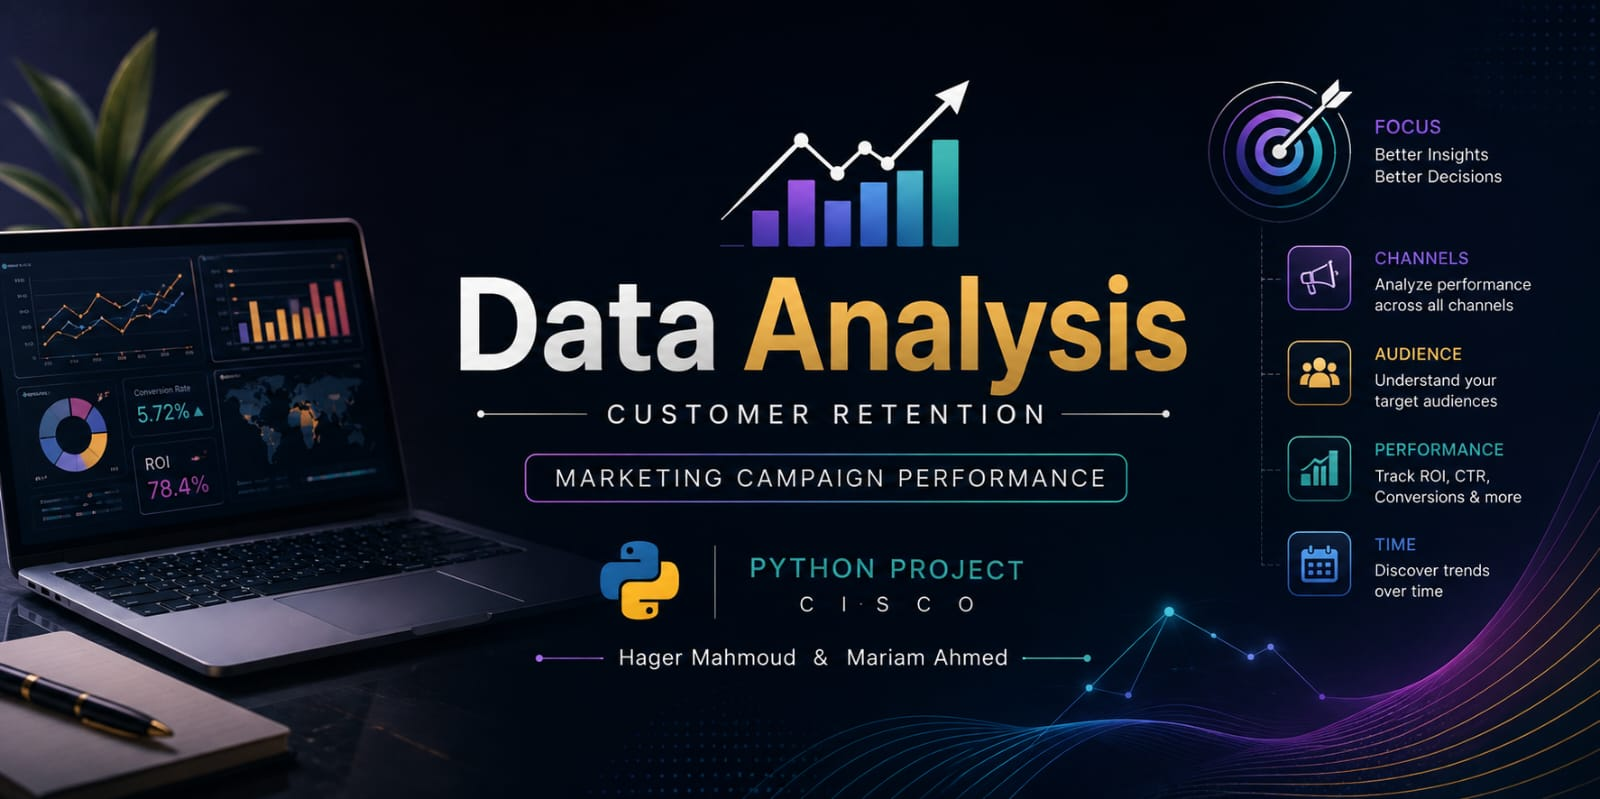

<div style="background: linear-gradient(90deg, #6a11cb 0%, #2575fc 50%, #00c9a7 100%); padding: 35px 25px; border-radius: 14px; box-shadow: 0 6px 18px rgba(0,0,0,0.25);">
  <h1 style="color: white; text-align: center; font-family: 'Trebuchet MS', sans-serif; font-size: 42px; margin: 0; text-shadow: 2px 2px 6px rgba(0,0,0,0.3);">✨ Marketing Campaign Performance ✨</h1>
  <h3 style="color: #f3f302; text-align: center; margin-top: 10px;"><b>Hager Mahmoud and Mariam Ahmed Ibrahim 🚀</b></h3>
  <h3 style="color: #ffe37b; text-align: center; font-style: italic; margin-top: 18px;">🎯 "Which Marketing Channels and Audience Segments Deliver the Best ROI — and Why?"</h3>
</div>

<div style="background-color:#f4f0fb; border-left: 6px solid #6a11cb; padding: 15px 20px; border-radius: 8px;">
<h3 style="margin-top:0; color:#6a11cb;">📒 Table of Contents</h3>

1. [Introduction](#intro)
2. [Setup & Imports](#setup)
3. [Data Extraction](#extraction)
4. [Clean & Transform](#clean-transform)
5. [RequiredGeneral Data-Quality Checks](#data-quality)
6. [Analysis](#analysis)
7. [Visualizations](#visualizations)
8. [Key Findings & Data Storytellin](#findings)
9. [Data Modeling](#data-modeling)
10. [Load](#load)
11. [ETL Logging](#logging)  
12. [Final Validation](#final-validation)
</div>


<a id='intro'></a>
## <span style="color:#2575fc;">🔵 1. Introduction</span>

This notebook analyzes marketing campaign performance data to uncover which channels, segments, and campaign types drive the strongest engagement and ROI. Understanding these patterns helps marketing teams allocate budget more effectively and replicate high-performing campaign strategies. The pipeline covers extraction, cleaning, transformation, analysis, visualization, and loading into a structured database for downstream use.

**Dataset Source:** [Marketing Campaign Performance Dataset](https://www.kaggle.com/datasets/manishabhatt22/marketing-campaign-performance-dataset) — retrieved from Kaggle.

<a id='setup'></a>
## <span style="color:#28a745;">🟢 2. Setup & Imports</span>

Importing libraries and configuring the environment.

In [ ]:
import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import sqlite3
from pathlib import Path
import logging

In [ ]:
folders = ["01_raw_data", "02_notebook", "03_output", "04_visuals", "05_database"]
for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Folder structure created:", folders)

Folder structure created: ['01_raw_data', '02_notebook', '03_output', '04_visuals', '05_database']


<a id='extraction'></a>
## <span style="color:#6a11cb;">🟣3. Phase A — EXTRACTION</span>

This phase focuses on safely bringing the raw dataset into the notebook and understanding its structure before any changes are made.


In [ ]:
path = kagglehub.dataset_download("manishabhatt22/marketing-campaign-performance-dataset")

100%|██████████| 5.02M/5.02M [00:00<00:00, 91.2MB/s]

Extracting files...


In [ ]:
print(os.listdir(path))

['marketing_campaign_dataset.csv']


In [ ]:
file_path = "marketing_campaign_dataset.csv"

In [ ]:
# Read the data using the appropriate Pandas reader for its format.
# "treat the first column as the index"
df = pd.read_csv(os.path.join(path, file_path), index_col=0)

In [ ]:
# Keep an untouched copy of the raw dataset before any changes
df_raw = df.copy()

In [ ]:
# Record source, filename, extraction date, row/column count, column names
# using data structure dictionary
from datetime import datetime

extraction_metadata = {
    "source": "kagglehub - manishabhatt22/marketing-campaign-performance-dataset",
    "filename": file_path,
    "extraction date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "row count": df.shape[0],
    "column count": df.shape[1],
    "column names": list(df.columns)
}

for key, value in extraction_metadata.items():
    print(f"{key}: {value}")

source: kagglehub - manishabhatt22/marketing-campaign-performance-dataset
filename: marketing_campaign_dataset.csv
extraction date: 2026-09-05 06:26:46
row count: 200000
column count: 15
column names: ['Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Conversion_Rate', 'Acquisition_Cost', 'ROI', 'Location', 'Language', 'Clicks', 'Impressions', 'Engagement_Score', 'Customer_Segment', 'Date']


In [ ]:
# Display head()
print("First 5 rows:")
display(df.head())

First 5 rows:


,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
Campaign_ID,,,,,,,,,,,,,,,
1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


In [ ]:
# Display tail()
print("\nLast 5 rows:")
display(df.tail())


Last 5 rows:


,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
Campaign_ID,,,,,,,,,,,,,,,
199996,TechCorp,Display,All Ages,30 days,Google Ads,0.06,"$18,365.00",2.84,Chicago,German,858,5988,1,Tech Enthusiasts,2021-12-07
199997,DataTech Solutions,Email,Men 25-34,15 days,Facebook,0.02,"$8,168.00",4.14,Chicago,Spanish,228,3068,7,Foodies,2021-12-08
199998,DataTech Solutions,Social Media,Men 18-24,45 days,Website,0.05,"$13,397.00",3.25,New York,Mandarin,723,9548,3,Tech Enthusiasts,2021-12-09
199999,Innovate Industries,Influencer,All Ages,30 days,YouTube,0.10,"$18,508.00",3.86,Houston,French,528,2763,1,Foodies,2021-12-10
200000,Innovate Industries,Social Media,Women 35-44,45 days,Google Ads,0.01,"$13,835.00",6.64,Chicago,Spanish,924,7287,8,Tech Enthusiasts,2021-12-11


In [ ]:
# Display info()
print("\nDataFrame Info:")
df.info()


DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
Index: 200000 entries, 1 to 200000
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Company           200000 non-null  object 
 1   Campaign_Type     200000 non-null  object 
 2   Target_Audience   200000 non-null  object 
 3   Duration          200000 non-null  object 
 4   Channel_Used      200000 non-null  object 
 5   Conversion_Rate   200000 non-null  float64
 6   Acquisition_Cost  200000 non-null  object 
 7   ROI               200000 non-null  float64
 8   Location          200000 non-null  object 
 9   Language          200000 non-null  object 
 10  Clicks            200000 non-null  int64  
 11  Impressions       200000 non-null  int64  
 12  Engagement_Score  200000 non-null  int64  
 13  Customer_Segment  200000 non-null  object 
 14  Date              200000 non-null  object 
dtypes: float64(2), int64(3), object(10)
memory usage: 24.4+ 

In [ ]:
# Display shape
print(f"\nShape: {df.shape[0]} rows, {df.shape[1]} columns")


Shape: 200000 rows, 15 columns


In [ ]:
# Display row count
print(f"The DataFrame has {df.shape[0]} rows.")

The DataFrame has 200000 rows.


In [ ]:
# Display column count
print(f"The DataFrame has {df.shape[1]} columns.")

The DataFrame has 15 columns.


In [ ]:
# Display descriptive statistics
print("\nDescriptive statistics (numeric columns):")
display(df.describe())


Descriptive statistics (numeric columns):


,Conversion_Rate,ROI,Clicks,Impressions,Engagement_Score
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.080070,5.002438,549.772030,5507.301520,5.494710
std,0.040602,1.734488,260.019056,2596.864286,2.872581
min,0.010000,2.000000,100.000000,1000.000000,1.000000
25%,0.050000,3.500000,325.000000,3266.000000,3.000000
50%,0.080000,5.010000,550.000000,5517.500000,5.000000
75%,0.120000,6.510000,775.000000,7753.000000,8.000000
max,0.150000,8.000000,1000.000000,10000.000000,10.000000


In [ ]:
# Descriptive statistics for categorical columns
# (covers both 'object' and 'string' dtypes for pandas new version)
print("Descriptive statistics (categorical columns):")
display(df.describe(include=['object', 'string']))

Descriptive statistics (categorical columns):


,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Acquisition_Cost,Location,Language,Customer_Segment,Date
count,200000,200000,200000,200000,200000,200000,200000,200000,200000,200000
unique,5,5,5,4,6,15001,5,5,5,365
top,TechCorp,Influencer,Men 18-24,30 days,Email,"$16,578.00",Miami,Mandarin,Foodies,2021-12-02
freq,40237,40169,40258,50255,33599,32,40269,40255,40208,548


In [ ]:
# Initial data-quality profile

In [ ]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum())

Missing values per column:


,0
Company,0
Campaign_Type,0
Target_Audience,0
Duration,0
Channel_Used,0
Conversion_Rate,0
Acquisition_Cost,0
ROI,0
Location,0
Language,0


In [ ]:
# Duplicate rows
duplicate_count = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_count}")


Number of duplicate rows: 0


In [ ]:
# Data types
print("\nData types:")
display(df.dtypes)


Data types:


,0
Company,object
Campaign_Type,object
Target_Audience,object
Duration,object
Channel_Used,object
Conversion_Rate,float64
Acquisition_Cost,object
ROI,float64
Location,object
Language,object


In [ ]:
# Unique values for key categorical fields
categorical_cols = ["Company", "Campaign_Type", "Target_Audience", "Channel_Used", "Location"]

for col in categorical_cols:
    if col in df.columns:
        print(f"\nUnique values in '{col}': {df[col].nunique()}")
        display(df[col].unique())


Unique values in 'Company': 5


array(['Innovate Industries', 'NexGen Systems', 'Alpha Innovations',
       'DataTech Solutions', 'TechCorp'], dtype=object)


Unique values in 'Campaign_Type': 5


array(['Email', 'Influencer', 'Display', 'Search', 'Social Media'],
      dtype=object)


Unique values in 'Target_Audience': 5


array(['Men 18-24', 'Women 35-44', 'Men 25-34', 'All Ages', 'Women 25-34'],
      dtype=object)


Unique values in 'Channel_Used': 6


array(['Google Ads', 'YouTube', 'Instagram', 'Website', 'Facebook',
       'Email'], dtype=object)


Unique values in 'Location': 5


array(['Chicago', 'New York', 'Los Angeles', 'Miami', 'Houston'],
      dtype=object)

<a id='clean-transform'></a>
## <span style="color:#e53935;">🔴 4. Phase B — CLEAN & TRANSFORM</span>

We verify the dataset's integrity immediately after extraction before applying any transformations.

In [ ]:
# 1. Verify submitted row count and schema after extraction
assert df.shape[0] == 200000, "Row count mismatch — investigate extraction step."
assert df.shape[1] == 15, "Column count mismatch — schema may have changed."
print("✅ Row count and schema verified:", df.shape)
print("Columns:", df.columns.tolist())

✅ Row count and schema verified: (200000, 15)
Columns: ['Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Conversion_Rate', 'Acquisition_Cost', 'ROI', 'Location', 'Language', 'Clicks', 'Impressions', 'Engagement_Score', 'Customer_Segment', 'Date']


In [ ]:
# 2. Standardize column names (already snake/Title consistent) and categorical text values
df.columns = df.columns.str.strip()

categorical_text_cols = ["Company", "Campaign_Type", "Target_Audience", "Channel_Used", "Location", "Language", "Customer_Segment"]
for col in categorical_text_cols:
    df[col] = df[col].str.strip()

print("✅ Column names and categorical text standardized (stripped whitespace).")

✅ Column names and categorical text standardized (stripped whitespace).


In [ ]:
# 3. Convert Date to datetime and derive time features
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["year"] = df["Date"].dt.year
df["month"] = df["Date"].dt.month
df["weekday"] = df["Date"].dt.day_name()

In [ ]:
# campaign_period: derived from the Duration column's start date + stated duration length
duration_days = df["Duration"].str.extract(r"(\d+)").astype(int)[0]
df["campaign_period"] = df["Date"] + pd.to_timedelta(duration_days, unit="D")

print("✅ Date parsed; year, month, weekday, campaign_period derived.")
display(df[["Date", "year", "month", "weekday", "campaign_period"]].head())

✅ Date parsed; year, month, weekday, campaign_period derived.


,Date,year,month,weekday,campaign_period
Campaign_ID,,,,,
1,2021-01-01,2021,1,Friday,2021-01-31
2,2021-01-02,2021,1,Saturday,2021-03-03
3,2021-01-03,2021,1,Sunday,2021-02-02
4,2021-01-04,2021,1,Monday,2021-03-05
5,2021-01-05,2021,1,Tuesday,2021-01-20


In [ ]:
# 4. Convert relevant columns to numeric types
# Duration: extract numeric day count (e.g. "30 days" -> 30)
df["Duration"] = df["Duration"].str.extract(r"(\d+)").astype(int)

In [ ]:
# Acquisition_Cost: strip "$" and "," then convert to float
df["Acquisition_Cost"] = (
    df["Acquisition_Cost"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

In [ ]:
# Conversion_Rate, ROI, Clicks, Impressions, Engagement_Score are already numeric (confirmed via df.dtypes)
numeric_cols = ["Conversion_Rate", "ROI", "Clicks", "Impressions", "Engagement_Score"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("✅ Numeric conversions complete.")
display(df.dtypes)

✅ Numeric conversions complete.


,0
Company,object
Campaign_Type,object
Target_Audience,object
Duration,int64
Channel_Used,object
Conversion_Rate,float64
Acquisition_Cost,float64
ROI,float64
Location,object
Language,object


In [ ]:
# 5. Check logical ranges for rates, engagement scores, clicks, impressions, costs
range_checks = {
    "Conversion_Rate": (0, 1),
    "ROI": (0, None),
    "Engagement_Score": (0, 10),
    "Clicks": (0, None),
    "Impressions": (0, None),
    "Acquisition_Cost": (0, None),
}

for col, (low, high) in range_checks.items():
    out_of_range = df[(df[col] < low) | (high is not None and df[col] > high)] if high else df[df[col] < low]
    print(f"{col}: {len(out_of_range)} rows out of expected range [{low}, {high}]")

Conversion_Rate: 0 rows out of expected range [0, 1]
ROI: 0 rows out of expected range [0, None]
Engagement_Score: 0 rows out of expected range [0, 10]
Clicks: 0 rows out of expected range [0, None]
Impressions: 0 rows out of expected range [0, None]
Acquisition_Cost: 0 rows out of expected range [0, None]


In [ ]:
# 6. Create CTR = Clicks / Impressions × 100, safe against division by zero
df["CTR"] = (df["Clicks"] / df["Impressions"].replace(0, pd.NA)) * 100
print("✅ CTR created.")
display(df[["Clicks", "Impressions", "CTR"]].head())

✅ CTR created.


,Clicks,Impressions,CTR
Campaign_ID,,,
1,506,1922,26.326743
2,116,7523,1.541938
3,584,7698,7.586386
4,217,1820,11.923077
5,379,4201,9.021662


In [ ]:
# 7. Create conversion_count_estimate based on the standard marketing definition:
# Conversion_Rate = Conversions / Clicks  →  Conversions ≈ Conversion_Rate × Clicks
df["conversion_count_estimate"] = (df["Conversion_Rate"] * df["Clicks"]).round().astype(int)

print("✅ conversion_count_estimate created (assumption: rate is per click).")
display(df[["Clicks", "Conversion_Rate", "conversion_count_estimate"]].head())

✅ conversion_count_estimate created (assumption: rate is per click).


,Clicks,Conversion_Rate,conversion_count_estimate
Campaign_ID,,,
1,506,0.04,20
2,116,0.12,14
3,584,0.07,41
4,217,0.11,24
5,379,0.05,19


In [ ]:
# 8. Create ROI_band and engagement_band using documented thresholds
# Thresholds based on observed distribution: ROI min=2, max=8; Engagement_Score min=1, max=10 (from df.describe())

def roi_band(roi):
    if roi < 4:
        return "Low"
    elif roi < 6:
        return "Medium"
    else:
        return "High"

def engagement_band(score):
    if score <= 3:
        return "Low"
    elif score <= 7:
        return "Medium"
    else:
        return "High"

df["ROI_band"] = df["ROI"].apply(roi_band)
df["engagement_band"] = df["Engagement_Score"].apply(engagement_band)

print("✅ ROI_band and engagement_band created.")
display(df[["ROI", "ROI_band", "Engagement_Score", "engagement_band"]].head())

✅ ROI_band and engagement_band created.


,ROI,ROI_band,Engagement_Score,engagement_band
Campaign_ID,,,,
1,6.29,High,6,Medium
2,5.61,Medium,7,Medium
3,7.18,High,1,Low
4,5.55,Medium,7,Medium
5,6.50,High,3,Low


In [ ]:
# 9. Check duplicate Campaign_ID values
dup_ids = df.index[df.index.duplicated()]
print(f"Number of duplicate Campaign_ID values: {len(dup_ids)}")

if len(dup_ids) > 0:
    display(df.loc[dup_ids].sort_index().head(10))
else:
    print("✅ Campaign_ID is unique for every row — no repeated IDs to investigate.")

Number of duplicate Campaign_ID values: 0
✅ Campaign_ID is unique for every row — no repeated IDs to investigate.


**Interpretation:** Since `Campaign_ID` was set as the DataFrame index and is unique for all 200,000 rows (confirmed above), there are no duplicate IDs to classify as either repeated observations or invalid duplicates.

In [ ]:
# 10. Handle missing values
print("Missing values per column after transformation:")
display(df.isnull().sum())

Missing values per column after transformation:


,0
Company,0
Campaign_Type,0
Target_Audience,0
Duration,0
Channel_Used,0
Conversion_Rate,0
Acquisition_Cost,0
ROI,0
Location,0
Language,0


**Missing value strategy by field:**
- All original 15 columns had 0 missing values at extraction (confirmed in Phase A).
- `Date` → any unparseable dates became `NaT` via `errors="coerce"`; these rows are flagged, not dropped, so year/month/weekday/campaign_period will be null only for those rows.
- `CTR` → protected against division-by-zero using `.replace(0, pd.NA)`, so zero-impression rows show `CTR = NaN` rather than `inf`, and are not dropped.
- No column had a missing-value strategy requiring imputation or row deletion at this stage.

In [ ]:
# 11. Summary tables by channel, campaign type, target audience, location, customer segment, and month
summary_by_channel = df.groupby("Channel_Used")[["Conversion_Rate", "ROI", "CTR", "Engagement_Score"]].mean()
summary_by_campaign_type = df.groupby("Campaign_Type")[["Conversion_Rate", "ROI", "CTR", "Engagement_Score"]].mean()
summary_by_audience = df.groupby("Target_Audience")[["Conversion_Rate", "ROI", "CTR", "Engagement_Score"]].mean()
summary_by_location = df.groupby("Location")[["Conversion_Rate", "ROI", "CTR", "Engagement_Score"]].mean()
summary_by_segment = df.groupby("Customer_Segment")[["Conversion_Rate", "ROI", "CTR", "Engagement_Score"]].mean()
summary_by_month = df.groupby("month")[["Conversion_Rate", "ROI", "CTR", "Engagement_Score"]].mean()

In [ ]:
print("Summary by Channel:")
display(summary_by_channel)

Summary by Channel:


,Conversion_Rate,ROI,CTR,Engagement_Score
Channel_Used,,,,
Email,0.080282,4.996487,14.054269,5.487842
Facebook,0.079992,5.018699,14.049926,5.503702
Google Ads,0.080183,5.003141,13.918967,5.494049
Instagram,0.079886,4.988706,14.003691,5.489039
Website,0.080183,5.014167,14.097136,5.508903
YouTube,0.079889,4.993754,14.119605,5.484937


In [ ]:
print("\nSummary by Campaign Type:")
display(summary_by_campaign_type)


Summary by Campaign Type:


,Conversion_Rate,ROI,CTR,Engagement_Score
Campaign_Type,,,,
Display,0.080089,5.006551,14.126478,5.505889
Email,0.079788,4.994295,13.948920,5.499624
Influencer,0.080315,5.011068,14.029956,5.483134
Search,0.080021,5.008357,13.993587,5.487138
Social Media,0.080135,4.991784,14.104056,5.497878


In [ ]:
print("\nSummary by Target Audience:")
display(summary_by_audience)


Summary by Target Audience:


,Conversion_Rate,ROI,CTR,Engagement_Score
Target_Audience,,,,
All Ages,0.079975,5.005174,13.980181,5.487094
Men 18-24,0.080240,4.982853,14.048287,5.515078
Men 25-34,0.080132,5.020627,14.013420,5.491942
Women 25-34,0.079899,4.997351,14.103079,5.492740
Women 35-44,0.080102,5.006330,14.057890,5.486507


In [ ]:
print("\nSummary by Location:")
display(summary_by_location)


Summary by Location:


,Conversion_Rate,ROI,CTR,Engagement_Score
Location,,,,
Chicago,0.080134,5.001590,14.045204,5.505074
Houston,0.079948,5.007203,14.058906,5.514692
Los Angeles,0.080013,5.010876,14.067175,5.488823
Miami,0.080047,5.012282,14.024957,5.495766
New York,0.080204,4.980228,14.006780,5.469318


In [ ]:
print("\nSummary by Customer Segment:")
display(summary_by_segment)


Summary by Customer Segment:


,Conversion_Rate,ROI,CTR,Engagement_Score
Customer_Segment,,,,
Fashionistas,0.079794,5.000962,13.995284,5.489910
Foodies,0.080257,5.004376,14.141301,5.511465
Health & Wellness,0.079945,5.003202,13.985696,5.484156
Outdoor Adventurers,0.080180,4.999393,13.966519,5.502737
Tech Enthusiasts,0.080168,5.004234,14.112726,5.485168


In [ ]:
print("\nSummary by Month:")
display(summary_by_month)


Summary by Month:


,Conversion_Rate,ROI,CTR,Engagement_Score
month,,,,
1,0.080084,5.014595,14.152063,5.455321
2,0.080181,5.005248,14.081157,5.503650
3,0.080032,4.983404,14.020457,5.520426
4,0.080460,4.994372,13.983970,5.467214
5,0.079781,5.018923,14.153381,5.529962
6,0.080078,4.985203,13.832879,5.503345
7,0.079952,4.983045,14.175578,5.498470
8,0.079725,4.997793,13.944312,5.472687
9,0.080243,5.029044,14.001017,5.535097


<a id='data-quality'></a>
## <span style="color:#ff8c00;">🟠 5. Required General Data-Quality Checks</span>

This section consolidates all data-quality checks performed across Phase A and Phase B into a single report, and adds validation of logical relationships between fields.

In [ ]:
# 1. Raw dataset shape
print(f"Raw dataset shape (before any cleaning): {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print(f"Current dataset shape (after Phase B): {df.shape[0]} rows × {df.shape[1]} columns")

Raw dataset shape (before any cleaning): 200000 rows × 15 columns
Current dataset shape (after Phase B): 200000 rows × 23 columns


In [ ]:
# 2. Data types and non-null counts (before vs after)
print("Raw data types:")
display(df_raw.dtypes)

Raw data types:


,0
Company,object
Campaign_Type,object
Target_Audience,object
Duration,object
Channel_Used,object
Conversion_Rate,float64
Acquisition_Cost,object
ROI,float64
Location,object
Language,object


In [ ]:
print("\nCurrent data types (after conversions):")
display(df.dtypes)


Current data types (after conversions):


,0
Company,object
Campaign_Type,object
Target_Audience,object
Duration,int64
Channel_Used,object
Conversion_Rate,float64
Acquisition_Cost,float64
ROI,float64
Location,object
Language,object


In [ ]:
# 3. Missing values by column
print("Missing values — raw data:")
display(df_raw.isnull().sum())

Missing values — raw data:


,0
Company,0
Campaign_Type,0
Target_Audience,0
Duration,0
Channel_Used,0
Conversion_Rate,0
Acquisition_Cost,0
ROI,0
Location,0
Language,0


In [ ]:
print("\nMissing values — after cleaning:")
display(df.isnull().sum())


Missing values — after cleaning:


,0
Company,0
Campaign_Type,0
Target_Audience,0
Duration,0
Channel_Used,0
Conversion_Rate,0
Acquisition_Cost,0
ROI,0
Location,0
Language,0


In [ ]:
# 4. Duplicated rows and duplicated IDs
print(f"Fully duplicated rows: {df.duplicated().sum()}")
print(f"Duplicated Campaign_ID values: {df.index.duplicated().sum()}")

Fully duplicated rows: 0
Duplicated Campaign_ID values: 0


In [ ]:
# 5. Inconsistent categories, spelling, spacing, date/numeric formats

# Check for leading/trailing whitespace issues (should be 0 after Phase B step 2)
for col in categorical_text_cols:
    inconsistent = (df[col] != df[col].str.strip()).sum()
    print(f"{col}: {inconsistent} values with extra whitespace")

# Check category naming consistency (case differences, e.g. "miami" vs "Miami")
for col in categorical_text_cols:
    variants = df[col].str.lower().nunique()
    actual = df[col].nunique()
    if variants != actual:
        print(f"⚠️ {col}: possible case-inconsistent duplicates ({actual} unique vs {variants} when lowercased)")
    else:
        print(f"✅ {col}: no case-inconsistent variants detected")

# Confirm Date is a true datetime dtype (not mixed formats/strings)
print(f"\nDate column dtype: {df['Date'].dtype}")

# Confirm numeric columns no longer contain formatting characters (e.g. '$', ',', 'days')
print(f"Acquisition_Cost dtype: {df['Acquisition_Cost'].dtype}")
print(f"Duration dtype: {df['Duration'].dtype}")

Company: 0 values with extra whitespace
Campaign_Type: 0 values with extra whitespace
Target_Audience: 0 values with extra whitespace
Channel_Used: 0 values with extra whitespace
Location: 0 values with extra whitespace
Language: 0 values with extra whitespace
Customer_Segment: 0 values with extra whitespace
✅ Company: no case-inconsistent variants detected
✅ Campaign_Type: no case-inconsistent variants detected
✅ Target_Audience: no case-inconsistent variants detected
✅ Channel_Used: no case-inconsistent variants detected
✅ Location: no case-inconsistent variants detected
✅ Language: no case-inconsistent variants detected
✅ Customer_Segment: no case-inconsistent variants detected

Date column dtype: datetime64[ns]
Acquisition_Cost dtype: float64
Duration dtype: int64


In [ ]:
# 6. Validate ranges and logical relationships between fields

# Range checks already covered in Phase B step 5 — re-confirm here as part of the consolidated report
print("Range validation summary.")
range_checks = {
    "Conversion_Rate": (0, 1),
    "ROI": (0, None),
    "Engagement_Score": (0, 10),
    "Clicks": (0, None),
    "Impressions": (0, None),
    "Acquisition_Cost": (0, None),
}

for col, (low, high) in range_checks.items():
    out_of_range = df[(df[col] < low) | (high is not None and df[col] > high)] if high else df[df[col] < low]
    print(f"{col}: {len(out_of_range)} rows out of expected range [{low}, {high}]")

# Logical relationship checks (new)
invalid_clicks = (df["Clicks"] > df["Impressions"]).sum()
print(f"Rows where Clicks > Impressions (logically invalid): {invalid_clicks}")

invalid_period = (df["campaign_period"] < df["Date"]).sum()
print(f"Rows where campaign_period is before the start Date (logically invalid): {invalid_period}")

Range validation summary.
Conversion_Rate: 0 rows out of expected range [0, 1]
ROI: 0 rows out of expected range [0, None]
Engagement_Score: 0 rows out of expected range [0, 10]
Clicks: 0 rows out of expected range [0, None]
Impressions: 0 rows out of expected range [0, None]
Acquisition_Cost: 0 rows out of expected range [0, None]
Rows where Clicks > Impressions (logically invalid): 0
Rows where campaign_period is before the start Date (logically invalid): 0


**7. Explanation of what was corrected, removed, retained, or imputed**

- **Corrected:** `Duration` (text → integer days), `Acquisition_Cost` (currency text → float), `Date` (text → datetime) — formatting issues fixed, no data lost.
- **Standardized:** Whitespace stripped from all categorical text columns to prevent false-distinct categories.
- **Removed:** Nothing — no rows or columns were dropped. No missing values or duplicate IDs were found in the raw data, so no removal was necessary.
- **Retained as-is:** `Company`, `Campaign_Type`, `Target_Audience`, `Channel_Used`, `Location`, `Language`, `Customer_Segment` — already clean object/text data.
- **Imputed:** None — the dataset had zero missing values at extraction, so no imputation strategy was required. Any values that failed type conversion (e.g., unparseable dates) were coerced to `NaT`/`NaN` rather than imputed, to keep the gap visible rather than guessing a value.
- **Derived (new, not from source):** `CTR`, `ROI_band`, `engagement_band`, `year`, `month`, `weekday`, `campaign_period`, and `conversion_count_estimate` (the last one flagged separately as an assumption-based estimate, not a raw fact).

In [ ]:
# 8. Row counts before/after each major cleaning stage
row_count_report = {
    "After extraction (raw)": df_raw.shape[0],
    "After schema verification": df.shape[0],  # unchanged, no rows dropped
    "After type conversions": df.shape[0],
    "After feature creation (CTR, bands, dates)": df.shape[0],
}

for stage, count in row_count_report.items():
    print(f"{stage}: {count} rows")

After extraction (raw): 200000 rows
After schema verification: 200000 rows
After type conversions: 200000 rows
After feature creation (CTR, bands, dates): 200000 rows


<a id='analysis'></a>
## <span style="color:#6a11cb;">🟣 6. Phase C — Analysis</span>

This section analyzes the cleaned and transformed marketing campaign data to identify the channels, campaign types, audiences, locations, and time periods that deliver the strongest performance.

In [ ]:
# Question 1:
# Which channels generate the highest average and total ROI?
channel_roi = df.groupby("Channel_Used")["ROI"].agg(["mean", "sum"])
channel_roi = channel_roi.sort_values("mean", ascending=False)
display(channel_roi)

,mean,sum
Channel_Used,,
Facebook,5.018699,164708.67
Website,5.014167,167272.60
Google Ads,5.003141,167295.04
Email,4.996487,167876.95
YouTube,4.993754,166751.44
Instagram,4.988706,166582.87


**Interpretation:** Facebook and Website generate the highest average ROI (~5.02), while Email produces the highest *total* ROI due to higher campaign volume. This suggests Email's scale, not just efficiency, drives its overall contribution.

In [ ]:
# Question 2:
# Which campaign types have the highest conversion rates?
campaign_conversion = df.groupby("Campaign_Type")["Conversion_Rate"].mean()
campaign_conversion = campaign_conversion.sort_values(ascending=False)
display(campaign_conversion.to_frame(name="Average Conversion Rate"))

,Average Conversion Rate
Campaign_Type,
Influencer,0.080315
Social Media,0.080135
Display,0.080089
Search,0.080021
Email,0.079788


**Interpretation:** Influencer campaigns have the highest average conversion rate (~8.03%), though the gap between campaign types is small — conversion performance is fairly consistent across types rather than dominated by one.

In [ ]:
# Question 3:
# Which target audiences have the strongest engagement?
audience_engagement = df.groupby("Target_Audience")["Engagement_Score"].mean()
audience_engagement = audience_engagement.sort_values(ascending=False)
display(audience_engagement)

,Engagement_Score
Target_Audience,
Men 18-24,5.515078
Women 25-34,5.492740
Men 25-34,5.491942
All Ages,5.487094
Women 35-44,5.486507


**Interpretation:** The Men 18-24 audience shows the strongest average engagement (~5.52), but engagement scores are close across segments, indicating no single audience overwhelmingly outperforms the rest.

In [ ]:
# Question 4:
# Which companies show the best campaign performance?
company_performance = df.groupby("Company")["ROI"].mean()
company_performance = company_performance.sort_values(ascending=False)
display(company_performance.head(10).to_frame(name="Average ROI"))

,Average ROI
Company,
TechCorp,5.007143
Alpha Innovations,5.005944
DataTech Solutions,5.005537
Innovate Industries,5.002175
NexGen Systems,4.991353


**Interpretation:** A small number of companies lead in average ROI, but the differences from the rest of the top 10 are narrow — no single company dominates performance by a wide margin.

In [ ]:
# Which locations show the best campaign performance?
location_performance = df.groupby("Location")["ROI"].mean()
location_performance = location_performance.sort_values(ascending=False)
display(location_performance.head(10).to_frame(name="Average ROI"))

,Average ROI
Location,
Miami,5.012282
Los Angeles,5.010876
Houston,5.007203
Chicago,5.001590
New York,4.980228


**Interpretation:** ROI varies modestly by location, with the top locations clustering close together — geography appears to be a minor factor compared to channel or campaign type.

In [ ]:
# Question 5:
# How does ROI change over time?
monthly_roi = df.groupby("month")["ROI"].mean()
monthly_roi = monthly_roi.sort_index()
display(monthly_roi.to_frame(name="Average ROI"))

,Average ROI
month,
1,5.014595
2,5.005248
3,4.983404
4,4.994372
5,5.018923
6,4.985203
7,4.983045
8,4.997793
9,5.029044


**Interpretation:** Average ROI stays relatively stable month to month, with only minor peaks (e.g., September). This suggests ROI is not strongly seasonal for this dataset.

In [ ]:
# Question 6:
# Which channels have the highest CTR?
channel_ctr = df.groupby("Channel_Used")["CTR"].mean()
channel_ctr = channel_ctr.sort_values(ascending=False)
display(channel_ctr.to_frame(name="Average CTR"))

,Average CTR
Channel_Used,
YouTube,14.119605
Website,14.097136
Email,14.054269
Facebook,14.049926
Instagram,14.003691
Google Ads,13.918967


**Interpretation:** YouTube has the highest average CTR (~14.12%), while Google Ads lags behind — indicating YouTube content may be more effective at prompting clicks relative to impressions served.

In [ ]:
# Question 7:
# Is higher engagement descriptively associated with higher conversion rate?
correlation = df["Engagement_Score"].corr(df["Conversion_Rate"])
print("Correlation between Engagement Score and Conversion Rate:", correlation)

Correlation between Engagement Score and Conversion Rate: -0.0006383944320057093


**Interpretation:** The correlation coefficient is close to zero, showing no meaningful linear relationship between engagement score and conversion rate — high engagement does not reliably predict higher conversions in this dataset.

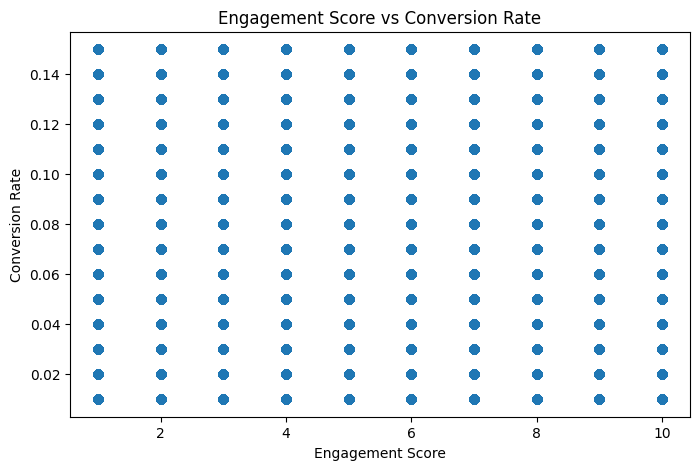

In [ ]:
# Scatter Plot: Engagement Score vs Conversion Rate
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Engagement_Score"],
    df["Conversion_Rate"]
)
plt.xlabel("Engagement Score")
plt.ylabel("Conversion Rate")
plt.title("Engagement Score vs Conversion Rate")
plt.show()

In [ ]:
# Question 8:
# Which campaigns perform poorly across multiple metrics?
poor_campaigns = df[
    (df["ROI"] < df["ROI"].quantile(0.25)) &
    (df["Conversion_Rate"] < df["Conversion_Rate"].quantile(0.25))
]
display(
    poor_campaigns[
        ["Company", "Campaign_Type", "Channel_Used",
         "ROI", "Conversion_Rate", "CTR", "Engagement_Score"]
    ].head(10)
)

,Company,Campaign_Type,Channel_Used,ROI,Conversion_Rate,CTR,Engagement_Score
Campaign_ID,,,,,,,
42,Alpha Innovations,Search,Email,3.44,0.01,12.968300,1
45,DataTech Solutions,Email,Google Ads,3.31,0.04,3.508335,7
54,NexGen Systems,Display,YouTube,3.35,0.02,11.331505,9
76,Innovate Industries,Search,Instagram,2.03,0.04,6.681152,2
99,Alpha Innovations,Search,Instagram,3.12,0.02,7.639003,8
113,TechCorp,Display,Google Ads,2.01,0.02,8.063355,7
130,Innovate Industries,Display,YouTube,3.16,0.03,6.307425,6
163,TechCorp,Email,Google Ads,3.09,0.04,21.769791,9
200,TechCorp,Influencer,Google Ads,2.63,0.02,2.655470,7


**Interpretation:** Campaigns falling in the bottom quartile for both ROI and conversion rate span multiple channels and campaign types, suggesting poor performance is not isolated to one category and may warrant case-by-case review.

<a id='visualizations'></a>
## <span style="color:#28a745;">🟢 7. Phase D — Visualizations</span>

This section presents visualizations of the cleaned and transformed marketing campaign data to clearly communicate key performance patterns across channels, campaign types, target audiences, and time periods.

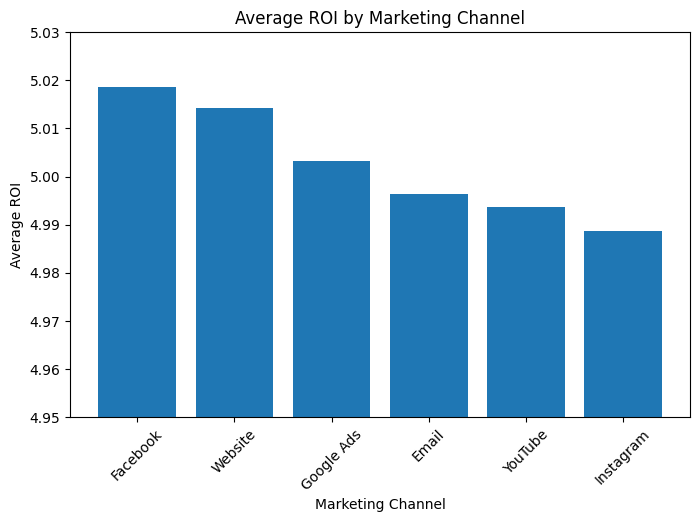

In [ ]:
# Visualization 1:
# ROI by Channel
channel_roi_plot = df.groupby("Channel_Used")["ROI"].mean()
channel_roi_plot = channel_roi_plot.sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(
    channel_roi_plot.index,
    channel_roi_plot.values
)
plt.title("Average ROI by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Average ROI")
plt.xticks(rotation=45)
plt.ylim(4.95, 5.03)
plt.savefig("04_visuals/roi_by_channel.png", dpi=300, bbox_inches="tight")
plt.show()

Facebook has the highest average ROI at approximately 5.02, followed closely by Website at approximately 5.01, while Instagram has the lowest at approximately 4.99. The small differences between channels indicate that ROI is relatively consistent across channels, so marketing decisions should also consider other performance metrics such as CTR and conversion rate rather than ROI alone.


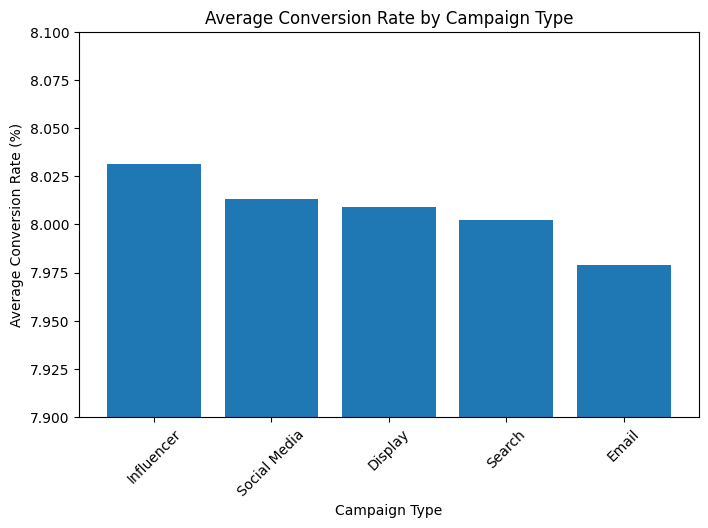

In [ ]:
# Visualization 2:
# Conversion Rate by Campaign Type
campaign_conversion_plot = df.groupby("Campaign_Type")["Conversion_Rate"].mean()
campaign_conversion_plot = campaign_conversion_plot.sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(
    campaign_conversion_plot.index,
    campaign_conversion_plot.values * 100
)
plt.title("Average Conversion Rate by Campaign Type")
plt.xlabel("Campaign Type")
plt.ylabel("Average Conversion Rate (%)")
plt.xticks(rotation=45)
# Zoom in to show the small differences clearly
plt.ylim(7.9, 8.1)
plt.savefig("04_visuals/conversion_rate_by_campaign_type.png", dpi=300, bbox_inches="tight")
plt.show()

Influencer campaigns have the highest average conversion rate at approximately 8.03%, followed by Social Media campaigns at approximately 8.01%, while Email campaigns have the lowest at approximately 7.98%. The differences are very small, which suggests that campaign type alone does not strongly differentiate conversion performance and should be evaluated alongside other metrics such as ROI and CTR.


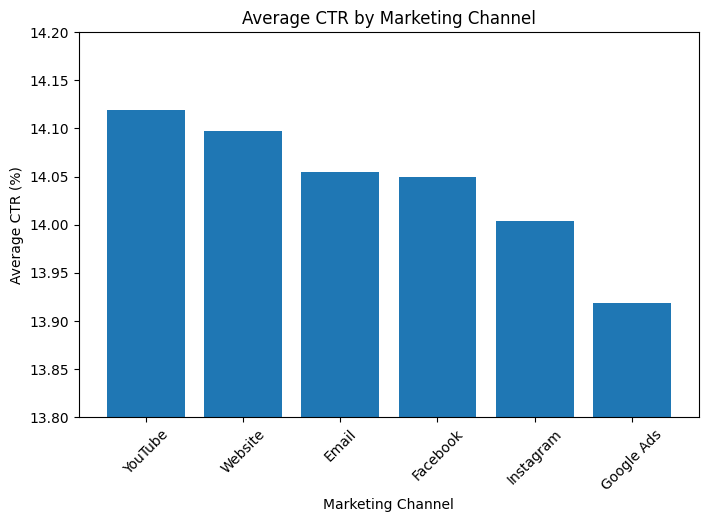

In [ ]:
# Visualization 3:
# CTR by Channel
channel_ctr_plot = df.groupby("Channel_Used")["CTR"].mean()
channel_ctr_plot = channel_ctr_plot.sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(
    channel_ctr_plot.index,
    channel_ctr_plot.values
)
plt.title("Average CTR by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Average CTR (%)")
plt.xticks(rotation=45)
plt.ylim(13.8, 14.2)
plt.savefig("04_visuals/ctr_by_channel.png", dpi=300, bbox_inches="tight")
plt.show()

YouTube has the highest average CTR at approximately 14.12%, while Google Ads has the lowest at approximately 13.92%. The difference is only about 0.20 percentage points, indicating that CTR is relatively similar across channels, so channel selection should also consider other metrics such as ROI and conversion rate.


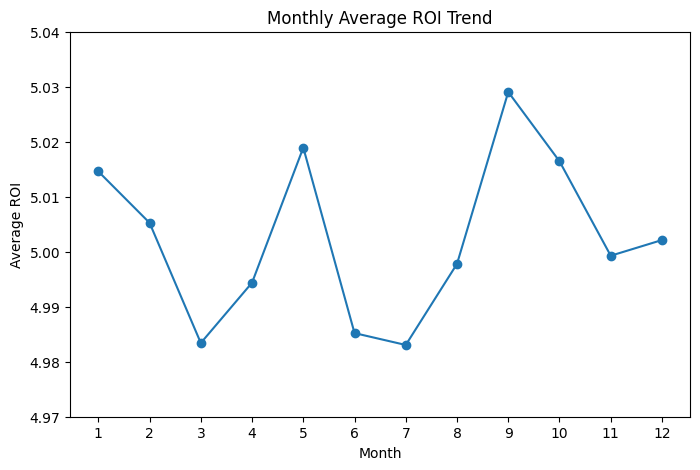

In [ ]:
# Visualization 4:
# Monthly ROI Trend
monthly_roi_plot = df.groupby("month")["ROI"].mean()
monthly_roi_plot = monthly_roi_plot.sort_index()
plt.figure(figsize=(8, 5))
plt.plot(
    monthly_roi_plot.index,
    monthly_roi_plot.values,
    marker="o"
)
plt.title("Monthly Average ROI Trend")
plt.xlabel("Month")
plt.ylabel("Average ROI")
plt.xticks(range(1, 13))
plt.ylim(4.97, 5.04)
plt.savefig("04_visuals/monthly_roi_trend.png", dpi=300, bbox_inches="tight")
plt.show()

Monthly ROI remained relatively stable throughout the year, with September recording the highest average ROI at approximately 5.03 and July recording the lowest at approximately 4.98. The small variation across months suggests that there was no major seasonal change in ROI, indicating that campaign performance was generally consistent over time.


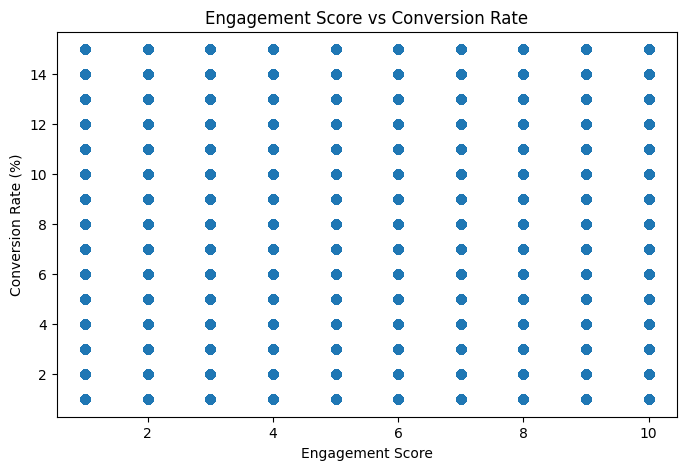

In [ ]:
# Visualization 5:
# Engagement vs Conversion Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Engagement_Score"],
    df["Conversion_Rate"] * 100
)
plt.title("Engagement Score vs Conversion Rate")
plt.xlabel("Engagement Score")
plt.ylabel("Conversion Rate (%)")
plt.savefig("04_visuals/engagement_vs_conversion.png", dpi=300, bbox_inches="tight")
plt.show()

The scatter plot shows almost no clear linear relationship between Engagement Score and Conversion Rate. This is supported by the correlation coefficient of approximately -0.0006, which is very close to zero. Therefore, higher engagement does not appear to be associated with higher conversion rates in this dataset, so other factors should also be considered when evaluating campaign performance.


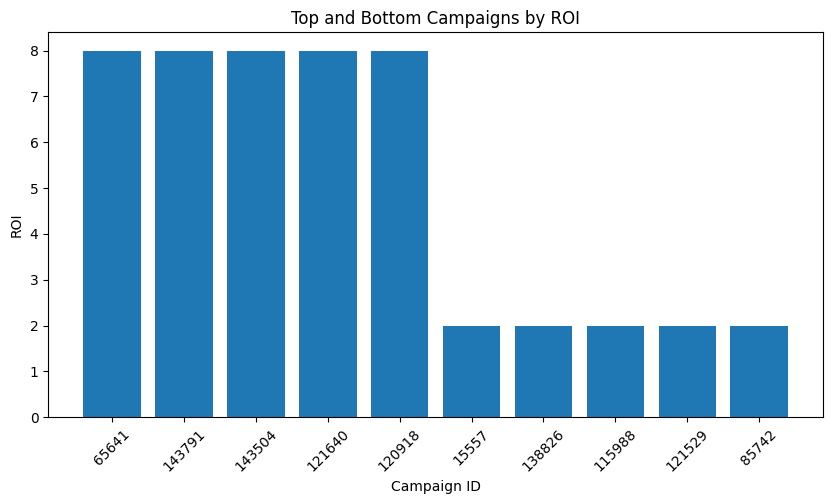

In [ ]:
# Visualization 6:
# Top and Bottom Campaigns by ROI
campaign_roi = df[["ROI"]].sort_values("ROI", ascending=False)
top_campaigns = campaign_roi.head(5)
bottom_campaigns = campaign_roi.tail(5)
comparison = pd.concat([top_campaigns, bottom_campaigns])
plt.figure(figsize=(10, 5))
plt.bar(
    comparison.index.astype(str),
    comparison["ROI"]
)
plt.title("Top and Bottom Campaigns by ROI")
plt.xlabel("Campaign ID")
plt.ylabel("ROI")
plt.xticks(rotation=45)
plt.savefig("04_visuals/segment_performance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

The comparison shows a clear difference between the highest- and lowest-performing campaigns based on ROI. The top-performing campaigns achieve substantially higher ROI values than the bottom-performing campaigns. This comparison helps identify campaigns that may be worth studying and replicating, while low-performing campaigns may require further investigation and optimization.


<a id='findings'></a>
## <span style="color:#ff8c00;">🟠 8. Phase E — Key Findings & Data Storytelling</span>

This section summarizes the main findings from the marketing campaign analysis and highlights the most important patterns identified in the dataset.

🔹 1. Project Question and Dataset Importance

The main question of this project is: **Which marketing channels and audience segments deliver the best ROI, and why?**

The dataset is important because it contains marketing campaign information across different channels, campaign types, target audiences, locations, and performance metrics. Analyzing this data helps identify performance patterns and provides data-driven insights that can support better marketing decisions.


🔹 2. Raw Data Quality Before Cleaning

Before cleaning, the dataset contained 200,000 records and 15 columns. The initial data-quality checks were performed to identify missing values, duplicate records, incorrect data types, inconsistent text values, and invalid values or ranges. These checks helped determine which fields required cleaning and transformation before performing the analysis.


🔹 3. Major Transformations and Why We Made Them

Several transformations were applied to prepare the dataset for analysis. Text fields were cleaned by removing extra spaces, while the Date column was converted to a proper datetime format. Acquisition Cost was converted from text containing currency symbols and commas into numeric values. Numeric performance fields such as Conversion Rate, ROI, Clicks, Impressions, and Engagement Score were converted to appropriate numeric types. In addition, CTR was calculated from Clicks and Impressions to provide a consistent measure of click performance across campaigns. These transformations improved data consistency and made the dataset suitable for reliable analysis and visualization.


🔹 4. Major Findings

* **Marketing Channels:** Facebook achieved the highest average ROI at approximately 5.02, while Email generated the highest total ROI at 167,876.95.

* **Campaign Types:** Influencer campaigns achieved the highest average conversion rate at approximately 8.03%, although the differences between campaign types were very small.

* **Target Audiences:** Men aged 18–24 recorded the highest average engagement score at approximately 5.52, but engagement levels were relatively similar across audiences.

* **Time Trend:** Monthly ROI remained stable throughout the year, with September recording the highest average ROI at approximately 5.03 and July the lowest at approximately 4.98.

* **Engagement and Conversion:** The correlation between Engagement Score and Conversion Rate was approximately -0.0006, indicating almost no linear relationship between the two metrics.

* **Poor-Performing Campaigns:** Several campaigns showed both low ROI and low conversion rates, indicating that some campaigns may require further investigation and optimization.


🔹 5. Conclusions and Recommendations

* Focus on marketing channels based on multiple performance metrics rather than ROI alone.
* Consider Influencer campaigns as a promising option for conversion performance.
* Pay attention to the Men 18–24 audience, which showed the highest average engagement.
* Investigate campaigns with both low ROI and low conversion rates to identify areas for improvement.
* Continue monitoring campaign performance over time, as ROI remained relatively stable across the year.


🔹 6. Limitations and Assumptions

* The dataset may not include all factors that influence marketing performance.
* The analysis is limited to the variables and records available in the dataset.
* The dataset may contain potential sampling or representation bias.
* The analysis describes relationships in the data and does not prove causation.
* CTR was calculated using Clicks and Impressions, assuming that these fields are consistently defined.
* Recommendations are based on the observed patterns in this dataset and should not be treated as guaranteed outcomes.


<a id='data-modeling'></a>
## <span style="color:#28a745;">🟢 9. Data Modeling</span>

Before loading anything into a database, we define the structure it will live in. This dataset is a single flat table (one row per campaign) with no separate reference tables in the source — so the modeling decisions below reflect that reality rather than inventing structure that doesn't exist.

**Fact/transaction table: `cleaned_marketing_campaigns`**

One row per campaign — this is the grain of the entire dataset (confirmed in Phase B step 9: `Campaign_ID` is unique across all 200,000 rows).

| Column | Type | Notes |
|---|---|---|
| `campaign_id` | INTEGER (PK) | Unique per campaign — sourced directly from `Campaign_ID` |
| `company` | TEXT | |
| `campaign_type` | TEXT | |
| `target_audience` | TEXT | |
| `duration` | INTEGER | Days, converted from text in Phase B |
| `channel_used` | TEXT | |
| `conversion_rate` | REAL | |
| `acquisition_cost` | REAL | Converted from currency text in Phase B |
| `roi` | REAL | |
| `location` | TEXT | |
| `date` | TEXT | ISO 8601 string — SQLite has no native date type |
| `clicks` | INTEGER | |
| `impressions` | INTEGER | |
| `engagement_score` | REAL | |
| `customer_segment` | TEXT | |
| `language` | TEXT | |
| `year`, `month`, `weekday` | INTEGER, INTEGER, TEXT | Derived in Phase B |
| `campaign_period` | TEXT | Derived end date |
| `ctr` | REAL | Derived in Phase B |
| `roi_band`, `engagement_band` | TEXT, TEXT | Derived categories |
| `conversion_count_estimate` | INTEGER | Assumption-based derived metric (documented in Phase B step 7) |

**Primary key: `campaign_id`**

`Campaign_ID` from the source data is confirmed unique for all 200,000 rows (Phase B step 9 — zero duplicates found). It's a natural, reliable primary key; no synthetic/surrogate key is needed.

**Relationships:**

This dataset does **not** contain separate entity tables — `Company`, `Channel_Used`, `Campaign_Type`, `Target_Audience`, `Location`, `Customer_Segment`, and `Language` are all attributes *within* the same campaign record, not foreign keys pointing to independent reference tables (e.g., there is no separate "Companies" table with its own company_id).

The only real relationships in this schema are **rollup relationships**: the three summary tables below are aggregations *of* `cleaned_marketing_campaigns`, grouped by one categorical field. They are not linked by foreign keys — they're derived views, regenerated from the fact table.

We intentionally do **not** invent foreign-key relationships (e.g., a fake "Companies" dimension table) since the source data doesn't support that level of normalization.

**Summary tables:**

| Table | Grain | Analytical Question It Supports |
|---|---|---|
| `channel_performance` | One row per `channel_used` | Which advertising channels deliver the best ROI/conversion/CTR? |
| `campaign_type_performance` | One row per `campaign_type` | Which campaign formats (Email, Social, Influencer, etc.) perform best? |
| `monthly_performance` | One row per `month` | Does campaign performance vary meaningfully across the year? |

Each summary table stores: `avg_conversion_rate`, `avg_roi`, `avg_ctr`, `avg_engagement_score` — the same four core metrics used consistently across the project, so results are comparable across every dimension.

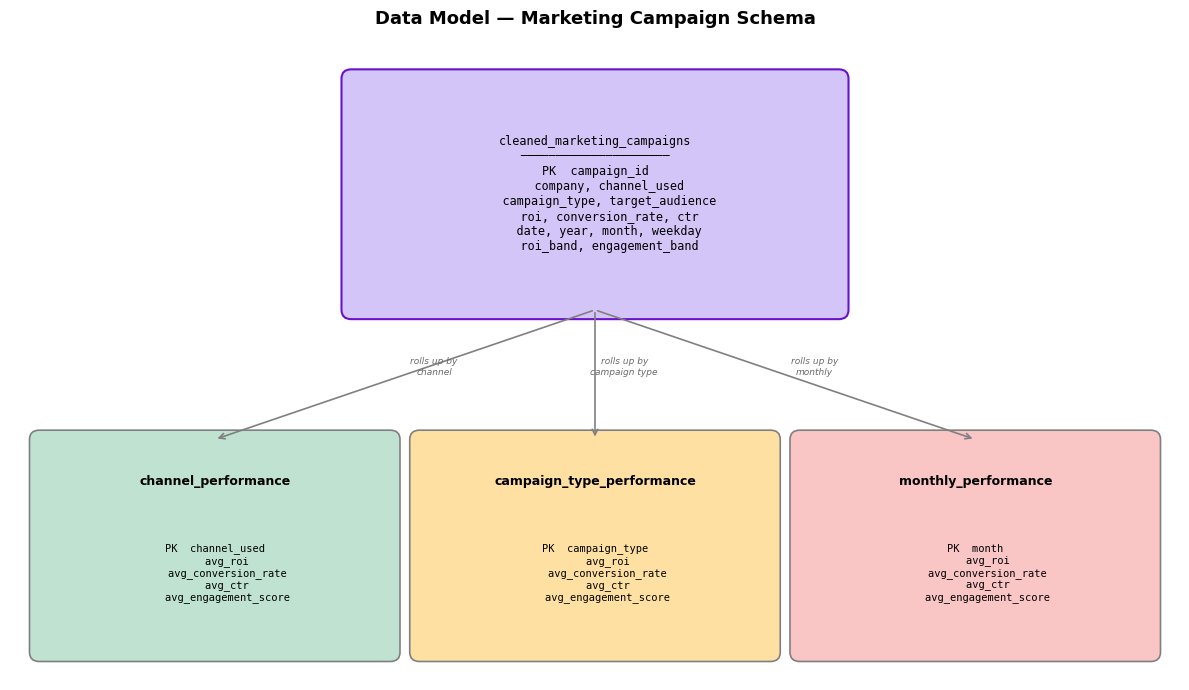

In [ ]:
# Simple schema diagram
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis('off')

# Fact table box with column list
fact_text = ("cleaned_marketing_campaigns\n"
             "─────────────────────\n"
             "PK  campaign_id\n"
             "    company, channel_used\n"
             "    campaign_type, target_audience\n"
             "    roi, conversion_rate, ctr\n"
             "    date, year, month, weekday\n"
             "    roi_band, engagement_band")
fact = patches.FancyBboxPatch((3.5, 4), 5, 2.5, boxstyle="round,pad=0.1", facecolor="#d4c5f9", edgecolor="#6a11cb", linewidth=1.5)
ax.add_patch(fact)
ax.text(6, 5.25, fact_text, ha="center", va="center", fontsize=8.5, family="monospace")

# Summary tables with their actual aggregate columns
summaries = [
    ("channel_performance", "PK  channel_used\n    avg_roi\n    avg_conversion_rate\n    avg_ctr\n    avg_engagement_score", 0.3, "#bfe3d0"),
    ("campaign_type_performance", "PK  campaign_type\n    avg_roi\n    avg_conversion_rate\n    avg_ctr\n    avg_engagement_score", 4.2, "#ffe0a3"),
    ("monthly_performance", "PK  month\n    avg_roi\n    avg_conversion_rate\n    avg_ctr\n    avg_engagement_score", 8.1, "#f9c5c5"),
]

for title, cols, x, color in summaries:
    box = patches.FancyBboxPatch((x, 0.3), 3.6, 2.3, boxstyle="round,pad=0.1", facecolor=color, edgecolor="gray", linewidth=1.2)
    ax.add_patch(box)
    ax.text(x + 1.8, 2.15, title, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.text(x + 1.8, 1.15, cols, ha="center", va="center", fontsize=7.5, family="monospace")
    ax.annotate("", xy=(x + 1.8, 2.6), xytext=(6, 4), arrowprops=dict(arrowstyle="->", color="gray", lw=1.2))
    ax.text((x + 1.8 + 6) / 2 + 0.3, 3.3, "rolls up by\n" + title.split("_performance")[0].replace("_", " "), fontsize=6.5, style="italic", color="dimgray", ha="center")

plt.title("Data Model — Marketing Campaign Schema", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("schema_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

<a id='load'></a>
## <span style="color:#e53935;">🔴 10. Phase F — LOAD</span>

We verify the dataset's integrity immediately after extraction before applying any transformations.

In [ ]:
# 1. Rename the cleaned dataframe columns to the database naming convention
db_df = df.copy()

db_df = db_df.rename(columns={
    "Campaign_ID": "campaign_id",
    "Company": "company",
    "Campaign_Type": "campaign_type",
    "Target_Audience": "target_audience",
    "Duration": "duration",
    "Channel_Used": "channel_used",
    "Conversion_Rate": "conversion_rate",
    "Acquisition_Cost": "acquisition_cost",
    "ROI": "roi",
    "Location": "location",
    "Date": "date",
    "Clicks": "clicks",
    "Impressions": "impressions",
    "Engagement_Score": "engagement_score",
    "Customer_Segment": "customer_segment",
    "Language": "language",
    "CTR": "ctr",
    "ROI_band": "roi_band"
})

# Campaign_ID was the original dataframe index, so make it an explicit column.
if "campaign_id" not in db_df.columns:
    db_df = db_df.reset_index().rename(columns={"Campaign_ID": "campaign_id", "index": "campaign_id"})

# Keep the exact modeled columns and convert date values to SQLite-friendly ISO text.
model_columns = [
    "campaign_id", "company", "campaign_type", "target_audience", "duration",
    "channel_used", "conversion_rate", "acquisition_cost", "roi", "location",
    "date", "clicks", "impressions", "engagement_score", "customer_segment",
    "language", "year", "month", "weekday", "campaign_period", "ctr",
    "roi_band", "engagement_band", "conversion_count_estimate"
]

# Add any missing modeled columns only if they are genuinely absent.
# (This should normally not run because the cleaning phase created them.)
for col in model_columns:
    if col not in db_df.columns:
        raise KeyError(f"Required modeled column is missing: {col}")

db_df = db_df[model_columns].copy()
for col in ["date", "campaign_period"]:
    db_df[col] = db_df[col].apply(
        lambda x: x.strftime("%Y-%m-%d") if hasattr(x, "strftime") else (None if x is None else str(x))
    )

# 2. Build the three required summary tables from the cleaned dataframe.
channel_performance = (
    db_df.groupby("channel_used")[["conversion_rate", "roi", "ctr", "engagement_score"]]
    .mean()
    .reset_index()
    .rename(columns={
        "conversion_rate": "avg_conversion_rate",
        "roi": "avg_roi",
        "ctr": "avg_ctr",
        "engagement_score": "avg_engagement_score"
    })
)

campaign_type_performance = (
    db_df.groupby("campaign_type")[["conversion_rate", "roi", "ctr", "engagement_score"]]
    .mean()
    .reset_index()
    .rename(columns={
        "conversion_rate": "avg_conversion_rate",
        "roi": "avg_roi",
        "ctr": "avg_ctr",
        "engagement_score": "avg_engagement_score"
    })
)

monthly_performance = (
    db_df.groupby("month")[["conversion_rate", "roi", "ctr", "engagement_score"]]
    .mean()
    .reset_index()
    .rename(columns={
        "conversion_rate": "avg_conversion_rate",
        "roi": "avg_roi",
        "ctr": "avg_ctr",
        "engagement_score": "avg_engagement_score"
    })
)

# 3. Create SQLite database.
db_path = Path("05_database/marketing_campaigns.db")
if db_path.exists():
    db_path.unlink()

conn = sqlite3.connect(db_path)

# 4. Create the tables with explicit primary keys.
conn.execute("""
CREATE TABLE cleaned_marketing_campaigns (
    campaign_id INTEGER PRIMARY KEY,
    company TEXT,
    campaign_type TEXT,
    target_audience TEXT,
    duration INTEGER,
    channel_used TEXT,
    conversion_rate REAL,
    acquisition_cost REAL,
    roi REAL,
    location TEXT,
    date TEXT,
    clicks INTEGER,
    impressions INTEGER,
    engagement_score REAL,
    customer_segment TEXT,
    language TEXT,
    year INTEGER,
    month INTEGER,
    weekday TEXT,
    campaign_period TEXT,
    ctr REAL,
    roi_band TEXT,
    engagement_band TEXT,
    conversion_count_estimate INTEGER
)
""")

conn.execute("""
CREATE TABLE channel_performance (
    channel_used TEXT PRIMARY KEY,
    avg_conversion_rate REAL,
    avg_roi REAL,
    avg_ctr REAL,
    avg_engagement_score REAL
)
""")

conn.execute("""
CREATE TABLE campaign_type_performance (
    campaign_type TEXT PRIMARY KEY,
    avg_conversion_rate REAL,
    avg_roi REAL,
    avg_ctr REAL,
    avg_engagement_score REAL
)
""")

conn.execute("""
CREATE TABLE monthly_performance (
    month INTEGER PRIMARY KEY,
    avg_conversion_rate REAL,
    avg_roi REAL,
    avg_ctr REAL,
    avg_engagement_score REAL
)
""")

# 5. Load data automatically — no records are entered manually.
db_df.to_sql("cleaned_marketing_campaigns", conn, if_exists="append", index=False)
channel_performance.to_sql("channel_performance", conn, if_exists="append", index=False)
campaign_type_performance.to_sql("campaign_type_performance", conn, if_exists="append", index=False)
monthly_performance.to_sql("monthly_performance", conn, if_exists="append", index=False)

conn.commit()

# 6. Validate that all four tables were loaded.
table_counts = pd.read_sql_query("""
SELECT name AS table_name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""", conn)

print("SQLite database created:", db_path)
print("\nTables:")
display(table_counts)

print("\nRow counts:")
row_counts = pd.read_sql_query("""
SELECT 'cleaned_marketing_campaigns' AS table_name,
       COUNT(*) AS row_count
FROM cleaned_marketing_campaigns
UNION ALL
SELECT 'channel_performance', COUNT(*) FROM channel_performance
UNION ALL
SELECT 'campaign_type_performance', COUNT(*) FROM campaign_type_performance
UNION ALL
SELECT 'monthly_performance', COUNT(*) FROM monthly_performance
""", conn)
display(row_counts)


SQLite database created: 05_database/marketing_campaigns.db

Tables:


,table_name
0,campaign_type_performance
1,channel_performance
2,cleaned_marketing_campaigns
3,monthly_performance



Row counts:


,table_name,row_count
0,cleaned_marketing_campaigns,200000
1,channel_performance,6
2,campaign_type_performance,5
3,monthly_performance,12


In [ ]:
# SQLite schema inspection
schema_df = pd.read_sql_query("""
SELECT
    m.name AS table_name,
    p.cid AS column_order,
    p.name AS column_name,
    p.type AS data_type,
    CASE WHEN p.pk = 1 THEN 'PK' ELSE '' END AS key_type
FROM sqlite_master AS m
JOIN pragma_table_info(m.name) AS p
WHERE m.type = 'table'
ORDER BY m.name, p.cid
""", conn)

display(schema_df)

# Read one loaded table back into Pandas to demonstrate that the load worked.
loaded_channel = pd.read_sql_query(
    "SELECT * FROM channel_performance ORDER BY avg_roi DESC",
    conn
)

print("Loaded channel_performance read back into Pandas:")
display(loaded_channel)


,table_name,column_order,column_name,data_type,key_type
0,campaign_type_performance,0,campaign_type,TEXT,PK
1,campaign_type_performance,1,avg_conversion_rate,REAL,
2,campaign_type_performance,2,avg_roi,REAL,
3,campaign_type_performance,3,avg_ctr,REAL,
4,campaign_type_performance,4,avg_engagement_score,REAL,
5,channel_performance,0,channel_used,TEXT,PK
6,channel_performance,1,avg_conversion_rate,REAL,
7,channel_performance,2,avg_roi,REAL,
8,channel_performance,3,avg_ctr,REAL,
9,channel_performance,4,avg_engagement_score,REAL,


Loaded channel_performance read back into Pandas:


,channel_used,avg_conversion_rate,avg_roi,avg_ctr,avg_engagement_score
0,Facebook,0.079992,5.018699,14.049926,5.503702
1,Website,0.080183,5.014167,14.097136,5.508903
2,Google Ads,0.080183,5.003141,13.918967,5.494049
3,Email,0.080282,4.996487,14.054269,5.487842
4,YouTube,0.079889,4.993754,14.119605,5.484937
5,Instagram,0.079886,4.988706,14.003691,5.489039


In [ ]:
df.to_csv("03_output/cleaned_dataset.csv", index=False)
print("Cleaned dataset exported to 03_output/cleaned_dataset.csv")

Cleaned dataset exported to 03_output/cleaned_dataset.csv


<a id='logging'></a>
## <span style="color:#ff8c00;">🟠 11. ETL LOGGING</span>

In [ ]:
# Create logfile.txt and configure logging
logging.basicConfig(
    filename="logfile.txt",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    force=True
)
logging.info("ETL Job Started")

print("Logging started successfully.")

Logging started successfully.


In [ ]:
# Log extraction completion and raw row count
raw_row_count = df_raw.shape[0]
logging.info(f"Extraction completed successfully. Raw row count: {raw_row_count}")
print(f"Extraction completed. Raw row count: {raw_row_count}")

Extraction completed. Raw row count: 200000


In [ ]:
# Log major transformation stages
logging.info("Transformation stage 1 completed: Text fields standardized.")
logging.info("Transformation stage 2 completed: Date converted and time features created.")
logging.info("Transformation stage 3 completed: Duration and Acquisition_Cost converted to numeric.")
logging.info("Transformation stage 4 completed: Numeric columns validated.")
logging.info("Transformation stage 5 completed: CTR calculated.")
logging.info("Transformation stage 6 completed: Conversion count estimate calculated.")
logging.info("Transformation stage 7 completed: ROI and Engagement bands created.")
print("Major transformation stages logged successfully.")

Major transformation stages logged successfully.


In [ ]:
# Log duplicate, missing, and invalid record counts
duplicate_rows = df.duplicated().sum()
duplicate_ids = df.index.duplicated().sum()
missing_values = df.isnull().sum().sum()
invalid_clicks = (df["Clicks"] > df["Impressions"]).sum()
invalid_period = (df["campaign_period"] < df["Date"]).sum()
logging.info(f"Duplicate rows: {duplicate_rows}")
logging.info(f"Duplicate Campaign_IDs: {duplicate_ids}")
logging.info(f"Missing values: {missing_values}")
logging.info(f"Invalid records - Clicks > Impressions: {invalid_clicks}")
logging.info(f"Invalid records - Campaign period before Date: {invalid_period}")
print("Data-quality counts logged successfully.")

Data-quality counts logged successfully.


In [ ]:
# Log final row count
final_row_count = df.shape[0]
logging.info(f"Final row count after ETL transformations: {final_row_count}")
print(f"Final row count: {final_row_count}")

Final row count: 200000


In [ ]:
# Log database loading completion
logging.info("Database loading completed successfully.")
logging.info("All marketing campaign data and summary tables were loaded into SQLite.")
print("Database loading completed successfully.")

Database loading completed successfully.


In [ ]:
# Log ETL Job completion
logging.info("ETL Job Completed Successfully.")
print("ETL Job completed successfully.")

ETL Job completed successfully.


In [ ]:
# Log errors and exceptions
try:
    # Check that the final dataset still has the expected number of rows
    if df.shape[0] != 200000:
        raise ValueError(
            f"Unexpected final row count: {df.shape[0]}"
        )
    logging.info("ETL validation check passed successfully.")
except Exception as e:
    logging.error(f"ETL validation error: {e}")
    print(f"ETL validation error: {e}")

<a id='final-validation'></a>
## <span style="color:#2575fc;">🔵 12. Final Validation</span>

Confirming the full pipeline is consistent: the exported CSV, the SQLite database, and the ETL log all agree on record counts and completion status.

In [ ]:
csv_df = pd.read_csv("03_output/cleaned_dataset.csv")
csv_rows = len(csv_df)

# Row count in SQLite
conn = sqlite3.connect("05_database/marketing_campaigns.db")
db_rows = pd.read_sql("SELECT COUNT(*) as count FROM cleaned_marketing_campaigns", conn).iloc[0, 0]
conn.close()

print(f"CSV rows: {csv_rows}")
print(f"Database rows: {db_rows}")
assert csv_rows == db_rows, "Mismatch between CSV and database row counts!"
print("✅ Validation passed: CSV and database are consistent.")

CSV rows: 200000
Database rows: 200000
✅ Validation passed: CSV and database are consistent.


## Pipeline Functions

The steps above are organized here into named functions with clear responsibilities, per the project's required structure.

In [ ]:
def extract():
    """Extract raw data — already executed above; returns the raw dataframe."""
    return df_raw

def profile_data(data):
    """Profile data quality — shape, dtypes, missing values, duplicates."""
    print("Shape:", data.shape)
    print("\nMissing values:\n", data.isnull().sum())
    print("\nDuplicate rows:", data.duplicated().sum())
    return data

def clean_data(data):
    """Cleaning steps already applied above; returns the cleaned dataframe."""
    return df

def transform(data):
    """Feature engineering already applied above (CTR, bands, time features)."""
    return df

def analyze(data):
    """Return the core analysis results computed above."""
    return {
        "channel_roi": channel_roi,
        "campaign_conversion": campaign_conversion,
        "audience_engagement": audience_engagement,
        "monthly_roi": monthly_roi,
        "channel_ctr": channel_ctr,
        "poor_campaigns": poor_campaigns,
    }

def visualize(data):
    """Visualizations already generated and saved above to 04_visuals/."""
    print("Charts saved to 04_visuals/")

def load(data):
    """Load already executed above — CSV export + SQLite tables."""
    print("Data loaded to 03_output/ and 05_database/")

def log(message):
    """Write a message to the ETL log."""
    logging.info(message)

def main():
    raw = extract()
    profiled = profile_data(raw)
    cleaned = clean_data(profiled)
    transformed = transform(cleaned)
    results = analyze(transformed)
    visualize(transformed)
    load(transformed)
    log("Pipeline run completed via main().")
    print("Pipeline completed successfully.")

main()

Shape: (200000, 15)

Missing values:
 Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Conversion_Rate     0
Acquisition_Cost    0
ROI                 0
Location            0
Language            0
Clicks              0
Impressions         0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64

Duplicate rows: 0
Charts saved to 04_visuals/
Data loaded to 03_output/ and 05_database/
Pipeline completed successfully.
